# Simulated Annealing Schedules

Michael Hahsler

In [7]:
import numpy as np
import matplotlib.pyplot as plt

## Cooling Schedules

### Exponential Schedule

See [1].

In [8]:
def temperature_exponential(time, initial_temperature, alpha):
    return initial_temperature * alpha**time

### Linear Schedule

See [1].

In [9]:
def temperature_linear(time, initial_temperature, eta):
    return initial_temperature - eta * time

### Fast Simulated Annealing

See [3].

In [10]:
def temperature_fast(time, initial_temperature):
    return initial_temperature / (1 + time)

### Logarithmic (Classic) Cooling

If $T_0$ is greater than or equal to the largest energy barrier in the problem, this schedule is guaranteed to find the global optimum in the limit of infinite time [2]. The schedule is defined for $t > 0$.

In [11]:
def temperature_logarithmic(time, initial_temperature):
    return initial_temperature / np.log1p(time)

## Comparison

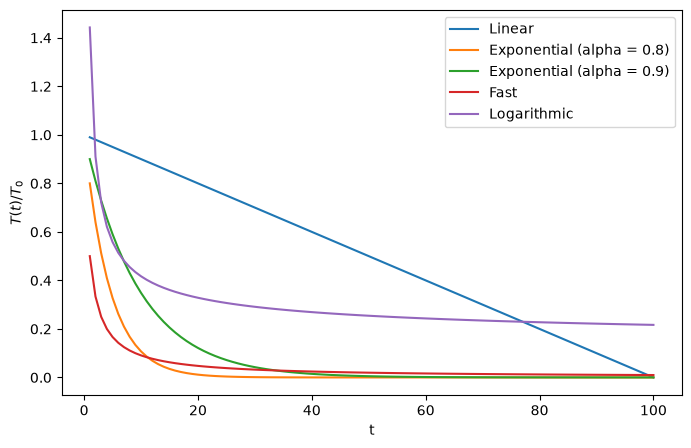

In [17]:
time = np.arange(1, 101)
initial_temperature = 1

schedules = {
    "Linear": temperature_linear(time, initial_temperature, eta=0.01),
    "Exponential (alpha = 0.8)": temperature_exponential(
        time, initial_temperature, alpha=0.8
    ),
    "Exponential (alpha = 0.9)": temperature_exponential(
        time, initial_temperature, alpha=0.9
    ),
    "Fast": temperature_fast(time, initial_temperature),
    "Logarithmic": temperature_logarithmic(time, initial_temperature),
}

plt.figure(figsize=(8, 5))
for name, temperature in schedules.items():
    plt.plot(time, temperature / initial_temperature, label=name)

plt.xlabel("t")
plt.ylabel(r"$T(t) / T_0$")
plt.legend()
plt.show()

## Khảo sát ảnh hưởng của alpha

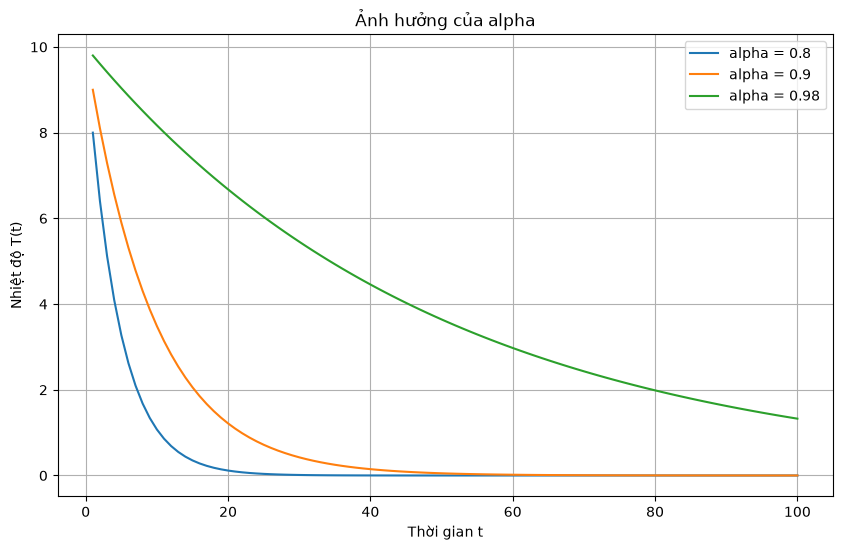

In [13]:
t = np.arange(1, 101)
T0 = 10

alphas = [0.8, 0.9, 0.98]

plt.figure(figsize=(10, 6))

for alpha in alphas:
    T = temperature_exponential(t, T0, alpha)
    plt.plot(t, T, label=f"alpha = {alpha}")

plt.xlabel("Thời gian t")
plt.ylabel("Nhiệt độ T(t)")
plt.title("Ảnh hưởng của alpha")
plt.legend()
plt.grid(True)
plt.show()

## Khảo sát ảnh hưởng của eta

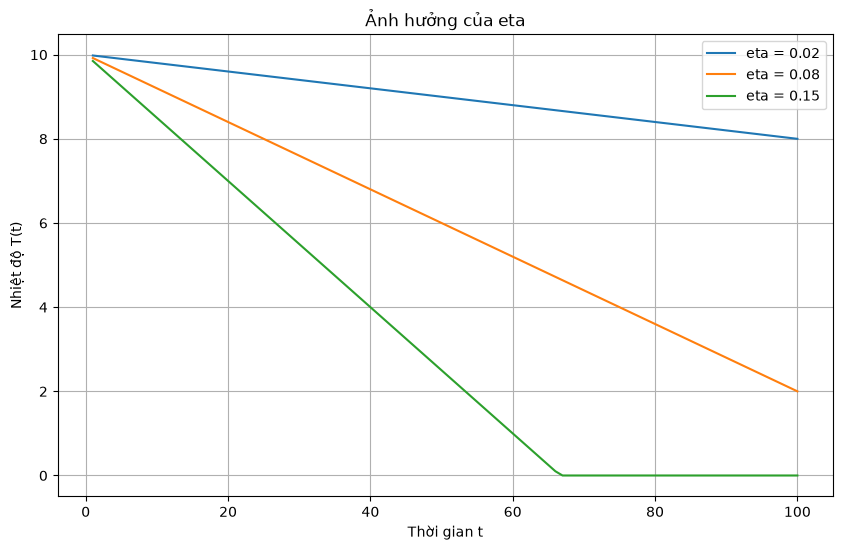

In [16]:
t = np.arange(1, 101)
T0 = 10

etas = [0.02, 0.08, 0.15]

plt.figure(figsize=(10, 6))

for eta in etas:
    T = temperature_linear(t, T0, eta)
    plt.plot(t, np.maximum(T, 0), label=f"eta = {eta}")

plt.xlabel("Thời gian t")
plt.ylabel("Nhiệt độ T(t)")
plt.title("Ảnh hưởng của eta")
plt.legend()
plt.grid(True)
plt.show()

## Khảo sát ảnh hưởng của nhiệt độ ban đầu

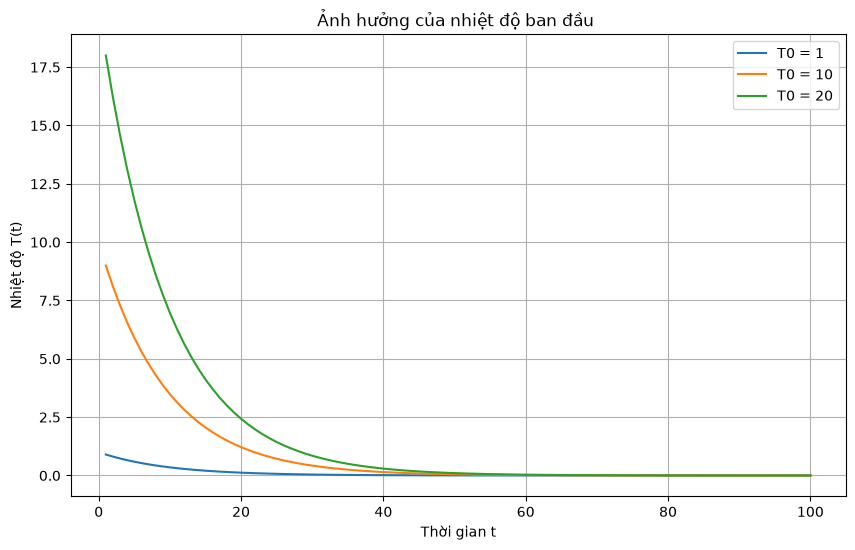

In [15]:
t = np.arange(1, 101)
T0_values = [1, 10, 20]

plt.figure(figsize=(10, 6))

for T0 in T0_values:
    T = temperature_exponential(t, T0, alpha=0.9)
    plt.plot(t, T, label=f"T0 = {T0}")

plt.xlabel("Thời gian t")
plt.ylabel("Nhiệt độ T(t)")
plt.title("Ảnh hưởng của nhiệt độ ban đầu ")
plt.legend()
plt.grid(True)
plt.show()

### Nhận xét kết quả khảo sát lịch giảm nhiệt độ

Qua đồ thị, ta thấy các lịch giảm nhiệt độ có tốc độ làm nguội khác nhau. Lịch Exponential phụ thuộc vào tham số alpha; alpha càng gần 1 thì nhiệt độ giảm càng chậm. Lịch Linear phụ thuộc vào eta; eta càng lớn thì nhiệt độ giảm càng nhanh. Lịch Fast giảm nhanh ở giai đoạn đầu, trong khi lịch Logarithmic có tốc độ giảm chậm hơn về lâu dài.

Nhiệt độ ảnh hưởng trực tiếp đến khả năng chấp nhận bước xấu của thuật toán Simulated Annealing. Khi nhiệt độ cao, thuật toán có khả năng chấp nhận bước làm tăng hàm mục tiêu lớn hơn; khi nhiệt độ thấp, thuật toán có xu hướng tập trung vào các bước cải thiện nghiệm.

Do đó, lịch giảm nhiệt độ chậm có thể giúp thuật toán khám phá nhiều trạng thái hơn nhưng cần nhiều thời gian. Ngược lại, lịch giảm nhiệt độ nhanh giúp giảm thời gian chạy nhưng có thể khiến thuật toán mắc kẹt ở nghiệm cục bộ. Hiệu quả thực tế cần được kiểm chứng bằng cách chạy Simulated Annealing trên bài toán N-Queens với cùng điều kiện thử nghiệm.

## Literature

1. Kirkpatrick, S., Gelatt, C. D. Jr., and Vecchi, M. P. (1983). Optimization by simulated annealing. *Science*, 220, 671–680.
2. Hajek, B. (1988). Cooling schedules for optimal annealing. *Mathematics of Operations Research*, 13, 311–329.
3. Szu, H., and Hartley, R. (1987). Fast simulated annealing. *Physics Letters A*, 122(3–4), 157–162. [doi:10.1016/0375-9601(87)90796-1](https://doi.org/10.1016/0375-9601(87)90796-1)